<a href="https://colab.research.google.com/github/schettinoezequiel7-design/ProcesamientoDelHabla/blob/main/Schettino_Ezequiel_TP2_Procesamiento_PDFs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ANÁLISIS DE PDF.**

# PDF ELEGIDO: Tipología de los contenidos virales de desinformación durante los primeros meses de emergencia sanitaria por la COVID-19 en el Perú.

# web del artículo: https://www.redalyc.org/articulo.oa?id=589475507011
# url del pdf: https://www.redalyc.org/journal/5894/589475507011/589475507011.pdf


# Para la realización del análisis mi apoyo fueron clases 1, 2, 3, 6 y 7 tanto a nivel teórico como práctico y el chat con Gemini Pro.

# **1. Adquisición de metadatos.**

# 1.1. Descarga.

# Para la descarga utilicé tanto requests y su HTTPAdapter para adaptar la configuración y de urllib3 el módulo Retry para los constantes reintentos de descargas.
# requests tiene una API más intuitiva y fácil de manejar y urllib tiene una mejor gestión frente a la mayor verbosidad y bajo nivel.

# Me costó la descarga con diversos códigos. Me fueron devueltos en reiteradas ocasiones: "404 Not Found", "Read time out", "503 Service Temporarity Unavailable".

# Todos estos errores, aparentemente tienen como causa el sistema de defensa contra bots de la web Redalyc. Me detectaba como un bot extrayendo en lotes información para otras causas, por esto mismo me tenía que detectar como un usuario que navegó en la web y buscó puntualmente este artículo.

In [ ]:
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

url_articulo = "https://www.redalyc.org/articulo.oa?id=589475507011" # Este es clave ya que lo incluyo para simular una visita real.
url_pdf = "https://www.redalyc.org/journal/5894/589475507011/589475507011.pdf" # Este es para la descarga.
nombre_archivo = "TDesinfPeru.pdf" # Yo le puse este nombre.

# Bloque de código para los reintentos automáticos.
session = requests.Session()
retries = Retry(total=5, backoff_factor=1, status_forcelist=[500, 502, 503, 504])
session.mount('https://', HTTPAdapter(max_retries=retries))

session.headers.update({
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8",
    "Referer": url_articulo,
    "Connection": "keep-alive"
}) # Estas son sesiones HTTP personalizadas para simular la visita a la web (url_articulo)

try:
    print("Conectando con el sitio web...")
    session.get(url_articulo, timeout=20)

    print("Intentando descargar el archivo PDF (esto puede tomar unos segundos)...")
    response = session.get(url_pdf, timeout=90, stream=True)
    # Pusimos un timeout de 90 segundos para darle tiempo a este proceso de simulación en la navegación de la web.
    response.raise_for_status()

    with open(nombre_archivo, "wb") as archivo: # Crea el archivo en el servidor de Colab en forma segura
        for bloque in response.iter_content(chunk_size=8192):
            if bloque: # Comprueba que el pdf no esté vacío (me paso con otros pdfs)
                archivo.write(bloque)

    print(f"¡PDF descargado exitosamente como '{nombre_archivo}'!")

except requests.exceptions.RequestException as e:
    print(f"Ocurrió un error persistente al descargar el archivo: {e}")

Conectando con el sitio web...
Intentando descargar el archivo PDF (esto puede tomar unos segundos)...
¡PDF descargado exitosamente como 'TDesinfPeru.pdf'!


# 1.2. Inspección.

# Para el análisis utilizo tanto PDFPlumber como PyMuPDF.

# La primera realiza análisis detallados de la estructura visual y optimización para la extracción de tablas, mientras que PyMuPDF mayor velocidad de procesamiento, extracción de texto plano en mayores cantidades e inclusión de herramientas avanzas de renderizado.

In [ ]:
!pip install pdfplumber pymupdf pandas requests -q

# Cotejo las versiones de las librerias con las que voy a trabajar.

In [ ]:
import pdfplumber
import pymupdf
import pandas as pd
import requests
import os

print("pdfplumber:", pdfplumber.__version__)
print("pymupdf:", pymupdf.__doc__.splitlines()[0] if pymupdf.__doc__ else pymupdf.version)
print("pandas:", pd.__version__)

pdfplumber: 0.11.10
pymupdf: PyMuPDF 1.28.2: Python bindings for the MuPDF 1.28.2 library.
pandas: 2.2.3


In [ ]:
pdf_plumber = pdfplumber.open("TDesinfPeru.pdf") # Guardo el pdf en cuestión dentro de la variable pdf_Plumber.

print("Tipo de objeto:", type(pdf_plumber))
print("Cantidad de páginas:", len(pdf_plumber.pages))

Tipo de objeto: <class 'pdfplumber.pdf.PDF'>
Cantidad de páginas: 28


In [ ]:
import pymupdf

def inspeccionar_pdf(nombre_archivo):
    """
    Abre un archivo PDF y muestra por pantalla la cantidad de páginas
    y sus metadatos (título, autor, software de creación, etc.).
    """
    # Abrir el documento
    doc = pymupdf.open(nombre_archivo)

    # Cantidad de páginas
    total_paginas = len(doc)
    print(f"📄 Número de páginas: {total_paginas}")

    # Metadatos del archivo
    print("\n📋 Metadatos del documento:")
    metadata = doc.metadata
    for clave, valor in metadata.items():
        print(f"  - {clave}: {valor}")

    # Cerrar el documento para liberar recursos
    doc.close()

    return total_paginas, metadata

In [ ]:
inspeccionar_pdf("TDesinfPeru.pdf")

📄 Número de páginas: 28

📋 Metadatos del documento:
  - format: PDF 1.4
  - title: 
  - author: 
  - subject: 
  - keywords: 
  - creator: Redalyc
  - producer: iText 2.1.7 by 1T3XT
  - creationDate: D:20230921150817-05'00'
  - modDate: D:20230921150817-05'00'
  - trapped: 
  - encryption: None


(28,
 {'format': 'PDF 1.4',
  'title': '',
  'author': '',
  'subject': '',
  'keywords': '',
  'creator': 'Redalyc',
  'producer': 'iText 2.1.7 by 1T3XT',
  'creationDate': "D:20230921150817-05'00'",
  'modDate': "D:20230921150817-05'00'",
  'trapped': '',
  'encryption': None})

In [ ]:
import pymupdf

def extraer_titulo_autor_primera_pagina(nombre_archivo, lineas_a_mostrar=15):
    doc = pymupdf.open(nombre_archivo)

    # Tomar la primera página (índice 0)
    primera_pagina = doc[0]

    # Extraer todo el texto de esa página
    texto = primera_pagina.get_text("text")

    # Separar el texto por saltos de línea para mostrar las primeras líneas
    lineas = texto.split('\n')

    print(f"📖 Primeras {lineas_a_mostrar} líneas de la primera página (Título / Autores):\n")
    for i in range(min(lineas_a_mostrar, len(lineas))):
        print(f"  {lineas[i]}")

    doc.close()
    return lineas

# Con esta función y en la inspección de las primeras líneas, me detecto los potenciales títulos, ya que infiere que estará por acá, pero no me lo llega a detectar con exactitud.

# En el output podemos ver el desorden y debemos realizar un trabajo de interpretación.

In [ ]:
extraer_titulo_autor_primera_pagina("TDesinfPeru.pdf")

📖 Primeras 15 líneas de la primera página (Título / Autores):

  Cómo citar el artículo
  Número completo
  Más información del artículo
  Página de la revista en redalyc.org
  Sistema de Información Científica Redalyc
  Red de Revistas Científicas de América Latina y el Caribe, España y Portugal
  Proyecto académico sin fines de lucro, desarrollado bajo la iniciativa de acceso
  abierto
  Revista de Comunicación
  ISSN: 1684-0933
  ISSN: 2227-1465
  Universidad de Piura. Facultad de Comunicación
  Pichihua Vegas, S. P.
  Tipología de los contenidos virales de desinformación durante los
  primeros meses de emergencia sanitaria por la COVID-19 en el Perú


['Cómo citar el artículo',
 'Número completo',
 'Más información del artículo',
 'Página de la revista en redalyc.org',
 'Sistema de Información Científica Redalyc',
 'Red de Revistas Científicas de América Latina y el Caribe, España y Portugal',
 'Proyecto académico sin fines de lucro, desarrollado bajo la iniciativa de acceso',
 'abierto',
 'Revista de Comunicación',
 'ISSN: 1684-0933',
 'ISSN: 2227-1465',
 'Universidad de Piura. Facultad de Comunicación',
 'Pichihua Vegas, S. P.',
 'Tipología de los contenidos virales de desinformación durante los',
 'primeros meses de emergencia sanitaria por la COVID-19 en el Perú',
 'Revista de Comunicación, vol. 21, núm. 2, 2022, pp. 197-223',
 'Universidad de Piura. Facultad de Comunicación',
 'DOI: https://doi.org/10.26441/RC21.2-2022-A10',
 'Disponible en: https://www.redalyc.org/articulo.oa?id=589475507011',
 '']

# **Prompt:** No usando la misma función, busca esto como título: Tipología de los contenidos virales de desinformación durante losprimeros meses de emergencia sanitaria por la COVID-19 en el Perú.

# Y como autor: Revista de Comunicación, vol. 21, núm. 2, 2022, pp. 197-223

# Notamos que le tuve que ser más específico, realizar una inspección manual para indicarle puntualmente el título y el autor y que sea un output correcto y prolijo.

In [ ]:
import pymupdf

def inspeccionar_consigna_pdf(nombre_archivo):
    doc = pymupdf.open(nombre_archivo)

    print("=== INSPECCIÓN DE METADATOS Y PROPIEDADES ===")

    # 1. Número de páginas
    total_paginas = len(doc)
    print(f"📄 Número de páginas: {total_paginas}")

    # 2. Software de creación
    metadata = doc.metadata
    software = metadata.get('producer') or metadata.get('creator') or "No especificado"
    print(f"💻 Software de creación: {software}")

    # 3. Extraer todo el texto de la primera página para buscar las cadenas exactas
    texto_portada = doc[0].get_text("text")

    # Definimos los valores solicitados
    titulo_buscado = "Tipología de los contenidos virales de desinformación durante los primeros meses de emergencia sanitaria por la COVID-19 en el Perú"
    autor_buscado = "Revista de Comunicación, vol. 21, núm. 2, 2022, pp. 197-223"

    # Verificación de coincidencia en el texto
    titulo = titulo_buscado if titulo_buscado.replace("\n", " ") in texto_portada.replace("\n", " ") else "Título no encontrado textualmente"
    autor = autor_buscado if autor_buscado in texto_portada else "Autor/Detalle no encontrado textualmente"

    print(f"✍️ Autor detectado: {autor}")
    print(f"📖 Título detectado: {titulo}")

    doc.close()

    return {
        "paginas": total_paginas,
        "titulo": titulo,
        "autor": autor,
        "software": software
    }

In [ ]:
inspeccionar_consigna_pdf("TDesinfPeru.pdf")

=== INSPECCIÓN DE METADATOS Y PROPIEDADES ===
📄 Número de páginas: 28
💻 Software de creación: iText 2.1.7 by 1T3XT
✍️ Autor detectado: Revista de Comunicación, vol. 21, núm. 2, 2022, pp. 197-223
📖 Título detectado: Tipología de los contenidos virales de desinformación durante los primeros meses de emergencia sanitaria por la COVID-19 en el Perú


{'paginas': 28,
 'titulo': 'Tipología de los contenidos virales de desinformación durante los primeros meses de emergencia sanitaria por la COVID-19 en el Perú',
 'autor': 'Revista de Comunicación, vol. 21, núm. 2, 2022, pp. 197-223',
 'software': 'iText 2.1.7 by 1T3XT'}

# **Prompt:** Que tipo de software es?

# **Respuesta:** Es una biblioteca de software libre en Java muy utilizada para la generación, lectura y manipulación programática de documentos PDF.

# **2. Análisis estructural del texto.**

# 2.1. Extracción cruda.

# Para la extracción y análisis del texto crudo, tomamos los códigos vistos en clase (semana 3, taller pdfs) y lo adaptamos a función.

# **Prompt:** Cuál es más eficiente y por qué?

# **Respuesta:** Ambos códigos realizan la extracción cruda del texto de todo el documento, pero el de PyMuPDF (7.2 Con PyMuPDF) es significativamente más eficiente y rápido por estar optimizado internamente en lenguaje C.

# Aquí tienes el desglose y la respuesta a los puntos de tu consigna:Extracción cruda:

# - Ambos recorren las páginas sumando el texto plano.

# - La función de pdfplumber es pagina.extract_text() y la de PyMuPDF es pagina.get_text() (o el atajó global doc.get_text()).   

# - Eficiencia: PyMuPDF gana por amplio margen en velocidad de procesamiento bruto y uso de memoria frente a pdfplumber.

# - Identificación de caracteres de separación: En ambos fragmentos, el carácter especial que funciona como separador de línea y de bloque al concatenar es el salto de línea "\n".   

# El lenguaje C beneficia enormemente el procesamiento de PDFs porque se ejecuta a nivel de hardware/sistema con velocidad nativa, evitando la lentitud interpretativa de Python. Esto permite que el motor procese estructuras pesadas, mapas de caracteres y miles de páginas en una fracción de tiempo y con un consumo mínimo de memoria.

In [ ]:
import pymupdf

def extraer_texto_crudo_pymupdf(nombre_archivo):
    # Abrir el documento
    doc = pymupdf.open(nombre_archivo)

    texto_completo_mupdf = ""

    # Recorrer cada página del documento de manera explícita
    for pagina in doc:
        texto_pagina = pagina.get_text()
        if texto_pagina:
            # Concatenar el texto de la página con un salto de línea como separador
            texto_completo_mupdf += texto_pagina + "\n"

    # Calcular métricas básicas del texto extraído
    total_caracteres = len(texto_completo_mupdf)
    total_palabras = len(texto_completo_mupdf.split())

    print(f"📄 Cantidad de caracteres extraídos (PyMuPDF): {total_caracteres}")
    print(f"📝 Cantidad de palabras aproximada: {total_palabras}")

    # Cerrar el documento para liberar recursos
    doc.close()

    return texto_completo_mupdf

In [ ]:
extraer_texto_crudo_pymupdf("TDesinfPeru.pdf")

📄 Cantidad de caracteres extraídos (PyMuPDF): 96934
📝 Cantidad de palabras aproximada: 13917


'Cómo citar el artículo\nNúmero completo\nMás información del artículo\nPágina de la revista en redalyc.org\nSistema de Información Científica Redalyc\nRed de Revistas Científicas de América Latina y el Caribe, España y Portugal\nProyecto académico sin fines de lucro, desarrollado bajo la iniciativa de acceso\nabierto\nRevista de Comunicación\nISSN: 1684-0933\nISSN: 2227-1465\nUniversidad de Piura. Facultad de Comunicación\nPichihua Vegas, S. P.\nTipología de los contenidos virales de desinformación durante los\nprimeros meses de emergencia sanitaria por la COVID-19 en el Perú\nRevista de Comunicación, vol. 21, núm. 2, 2022, pp. 197-223\nUniversidad de Piura. Facultad de Comunicación\nDOI: https://doi.org/10.26441/RC21.2-2022-A10\nDisponible en: https://www.redalyc.org/articulo.oa?id=589475507011\n\nRevista de Comunicación, 2022, vol. 21, N° 2. E-ISSN: 2227-1465\n197\nTipología de los contenidos virales de \ndesinformación durante los primeros meses de \nemergencia sanitaria por la COV

# 2.2. Análisis de separadores.

# '\n' separa líneas dentro de un mismo parrafo o elementos consecutivos cortos (títulos, subtítulos, etc.).

# '\n\n' separa párrafos.

In [ ]:
texto_crudo = extraer_texto_crudo_pymupdf("TDesinfPeru.pdf")
print(texto_crudo[:4000])

📄 Cantidad de caracteres extraídos (PyMuPDF): 96934
📝 Cantidad de palabras aproximada: 13917
Cómo citar el artículo
Número completo
Más información del artículo
Página de la revista en redalyc.org
Sistema de Información Científica Redalyc
Red de Revistas Científicas de América Latina y el Caribe, España y Portugal
Proyecto académico sin fines de lucro, desarrollado bajo la iniciativa de acceso
abierto
Revista de Comunicación
ISSN: 1684-0933
ISSN: 2227-1465
Universidad de Piura. Facultad de Comunicación
Pichihua Vegas, S. P.
Tipología de los contenidos virales de desinformación durante los
primeros meses de emergencia sanitaria por la COVID-19 en el Perú
Revista de Comunicación, vol. 21, núm. 2, 2022, pp. 197-223
Universidad de Piura. Facultad de Comunicación
DOI: https://doi.org/10.26441/RC21.2-2022-A10
Disponible en: https://www.redalyc.org/articulo.oa?id=589475507011

Revista de Comunicación, 2022, vol. 21, N° 2. E-ISSN: 2227-1465
197
Tipología de los contenidos virales de 
desinform

In [ ]:
texto_crudo[:96934]

'Cómo citar el artículo\nNúmero completo\nMás información del artículo\nPágina de la revista en redalyc.org\nSistema de Información Científica Redalyc\nRed de Revistas Científicas de América Latina y el Caribe, España y Portugal\nProyecto académico sin fines de lucro, desarrollado bajo la iniciativa de acceso\nabierto\nRevista de Comunicación\nISSN: 1684-0933\nISSN: 2227-1465\nUniversidad de Piura. Facultad de Comunicación\nPichihua Vegas, S. P.\nTipología de los contenidos virales de desinformación durante los\nprimeros meses de emergencia sanitaria por la COVID-19 en el Perú\nRevista de Comunicación, vol. 21, núm. 2, 2022, pp. 197-223\nUniversidad de Piura. Facultad de Comunicación\nDOI: https://doi.org/10.26441/RC21.2-2022-A10\nDisponible en: https://www.redalyc.org/articulo.oa?id=589475507011\n\nRevista de Comunicación, 2022, vol. 21, N° 2. E-ISSN: 2227-1465\n197\nTipología de los contenidos virales de \ndesinformación durante los primeros meses de \nemergencia sanitaria por la COV

# Usando 'print' me lo ordena estructuralmente y sin 'print' me da el texto crudo.

# Conteo de otros caracteres para visualizar su existencia y mejorar la conceptualización de la estructura del pdf.

# 2.3. Identificación de caracteres.

In [ ]:
def identificar_caracteres_separadores(texto):
    conteo = {
        "Saltos de línea (\\n)": texto.count('\n'),
        "Retornos de carro (\\r)": texto.count('\r'),
        "Tabulaciones (\\t)": texto.count('\t'),
        "Bloques de espacios múltiples": texto.count('  ')
    }

    print("🔍 Resultados de identificación de caracteres separadores:")
    for caracter, cantidad in conteo.items():
        print(f"  - {caracter}: {cantidad} ocurrencias encontradas")

    return conteo

In [ ]:
identificar_caracteres_separadores(texto_crudo)

🔍 Resultados de identificación de caracteres separadores:
  - Saltos de línea (\n): 1377 ocurrencias encontradas
  - Retornos de carro (\r): 0 ocurrencias encontradas
  - Tabulaciones (\t): 5 ocurrencias encontradas
  - Bloques de espacios múltiples: 58 ocurrencias encontradas


{'Saltos de línea (\\n)': 1377,
 'Retornos de carro (\\r)': 0,
 'Tabulaciones (\\t)': 5,
 'Bloques de espacios múltiples': 58}

# Notamos que además utiliza '\t' y '\\t' utilizado normalmente para realizar tabulaciones y tablas.

# **3. Extracción de datos tabulares.**

# **Prompt:** Para encontrar la tabla en el pdf, q manera tengo para hacerlo?

# **Respuesta:** Tienes dos formas principales: de manera visual (buscando en el texto crudo palabras clave como "Tabla", "Cuadro" o viendo la estructura del documento) o de forma programática (recorriendo las páginas con un bucle en Python usando pdfplumber y su método de detección para ver qué página arroja datos tabulares).

# 3.1. Extracción e inspección de tablas.

# Para la búsqueda y extracción de tablas, primero utilizamos un código creado junto con Gemini. Este me da tabla con una estructura "cruda". No es tan facilmente legible.

# Utilizamos Pandas para ordenar las tablas en DataFrames.

In [ ]:
import pdfplumber
import pandas as pd

def extraer_todas_tablas_pdfplumber(nombre_archivo):
    tablas_extraidas = []

    with pdfplumber.open(nombre_archivo) as pdf:
        for num_pagina, pagina in enumerate(pdf.pages, start=1):
            # Extrae las tablas de la página actual
            tablas_pagina = pagina.extract_tables()

            if tablas_pagina:
                for idx, tabla in enumerate(tablas_pagina):
                    # Convertimos la tabla cruda en DataFrame de Pandas
                    df = pd.DataFrame(tabla)

                    # Limpieza básica inicial (asignar primera fila como encabezado si aplica)
                    if not df.empty:
                        df.columns = df.iloc[0]  # Toma la primera fila como nombres de columna
                        df = df[1:].reset_index(drop=True)  # Remueve la fila de encabezado original
                        # Eliminar filas completamente vacías
                        df = df.dropna(how='all').reset_index(drop=True)

                    tablas_extraidas.append({
                        "pagina": num_pagina,
                        "tabla_index": idx + 1,
                        "dataframe": df
                    })

    print(f"📄 [pdfplumber] Se encontraron {len(tablas_extraidas)} tablas en total.")
    return tablas_extraidas

lista_tablas_plumber = extraer_todas_tablas_pdfplumber("TDesinfPeru.pdf")

📄 [pdfplumber] Se encontraron 6 tablas en total.


In [ ]:
lista_tablas_plumber

[{'pagina': 8,
  'tabla_index': 1,
  'dataframe': 0         Convoca                                               None  \
  0       Verdadero  Se comprobó la\nveracidad de la\nafirmación o ...   
  1           Falso  Se comprobó la\nfalsedad de la\nafirmación o n...   
  2      Discutible  La afirmación o\nnoticia está abierta al\ndeba...   
  3        Engañoso  La afirmación o noticia\ncoincide parcialmente...   
  4       Verdadero  La afirmación o noticia\nno es completamente\n...   
  5  No verificable  La afirmación o\nnoticia no puede\nser contras...   
  
  0 La República                                               None  \
  0       Cierto                              Contenido verificado.   
  1        Falso                          Contenido no\nverificado.   
  2    Impreciso  La información es\ninsostenible o no hay\nelem...   
  3     Engañoso  El contenido se genera\na partir de elementos\...   
  4                                                                   
  5  

# Por otro lado, probamos utilizar otro modo, con "!pip install tabula-py". Pero al no tener Java, al menos este Colab ahora, no logramos usarlo.

# Es otra manera de gestionar las tablas en un pdf de texto.

# Este es el código utilizado en clase, adaptado a función. Genera un output similar al anterior. Pero en el anterior vemos al utilizar pd.DataFrame la diferencia en el orden y visualización.

In [ ]:
import pdfplumber

def buscar_y_mostrar_tablas_pdfplumber(nombre_archivo):
    with pdfplumber.open(nombre_archivo) as pdf:
        tablas_encontradas = 0

        for num_pagina, pagina in enumerate(pdf.pages, start=1):
            tabla_cruda = pagina.extract_table()

            # Si `extract_table()` no devuelve None ni una tabla vacía
            if tabla_cruda:
                tablas_encontradas += 1
                print(f"\n--- Tabla encontrada en la Página {num_pagina} ---")
                print(f"Tipo de dato: {type(tabla_cruda)}")
                print(f"Cantidad de filas: {len(tabla_cruda)}")
                print("Primeras 3 filas:")
                for fila in tabla_cruda[:3]:
                    print(fila)

        if tablas_encontradas == 0:
            print("No se encontraron tablas estructuradas con este método en el documento.")
        else:
            print(f"\nTotal de tablas encontradas y procesadas: {tablas_encontradas}")

In [ ]:
buscar_y_mostrar_tablas_pdfplumber("TDesinfPeru.pdf")


--- Tabla encontrada en la Página 8 ---
Tipo de dato: <class 'list'>
Cantidad de filas: 7
Primeras 3 filas:
['Convoca', None, 'La República', None, 'Ojo Público', None]
['Verdadero', 'Se comprobó la\nveracidad de la\nafirmación o noticia\nluego de contrastarla\ncon diversas fuentes y\ndatos oficiales.', 'Cierto', 'Contenido verificado.', 'Verdadero', 'El dato o la afirmación\ntiene sustento verificable\nen una base de\ndatos oficial o fuente\nalternativa calificada\n(academia, think tanks,\nsociedad civil).']
['Falso', 'Se comprobó la\nfalsedad de la\nafirmación o noticia\nluego de contrastarla\ncon diversas fuentes y\ndatos oficiales.', 'Falso', 'Contenido no\nverificado.', 'Falso', 'El dato o información es\ndesmentido de manera\nconcluyente por la propia\nevidencia oficial o, en\nsu ausencia, de fuente\nalternativa calificada.']

--- Tabla encontrada en la Página 13 ---
Tipo de dato: <class 'list'>
Cantidad de filas: 11
Primeras 3 filas:
['Medios digitales usados', 'Cantidad']
['We

# 3.2. Conversión a dataframe.

In [ ]:
import pdfplumber
import pandas as pd

def mostrar_todas_las_tablas_ordenadas(nombre_archivo):
    with pdfplumber.open(nombre_archivo) as pdf:
        contador_tabla = 0

        for num_pagina, pagina in enumerate(pdf.pages, start=1):
            tablas_en_pagina = pagina.extract_tables()

            if tablas_en_pagina:
                for tabla_cruda in tablas_en_pagina:
                    if tabla_cruda and len(tabla_cruda) > 1:
                        contador_tabla += 1

                        # Aplicar la lógica vista en clase
                        encabezados = tabla_cruda[0]
                        filas_datos = tabla_cruda[1:]

                        # Crear el DataFrame de Pandas
                        df = pd.DataFrame(filas_datos, columns=encabezados)

                        # Limpiar filas vacías si las hay
                        df = df.dropna(how='all').reset_index(drop=True)

                        print(f"\n{'='*40}")
                        print(f"📊 TABLA N° {contador_tabla} (Página {num_pagina})")
                        print(f"{'='*40}")
                        try:
                            from IPython.display import display
                            display(df)
                        except ImportError:
                            print(df)

# **Prompt:** Dado q hay 6 tablas, me gustaría q me las ordene por sus números y q pueda ver cada salida de esta manera por separado. El código este es a modo de ejemplo.



In [ ]:
mostrar_todas_las_tablas_ordenadas("TDesinfPeru.pdf")


📊 TABLA N° 1 (Página 8)


,Convoca,None,La República,None,Ojo Público,None
0,Verdadero,Se comprobó la\nveracidad de la\nafirmación o ...,Cierto,Contenido verificado.,Verdadero,El dato o la afirmación\ntiene sustento verifi...
1,Falso,Se comprobó la\nfalsedad de la\nafirmación o n...,Falso,Contenido no\nverificado.,Falso,El dato o información es\ndesmentido de manera...
2,Discutible,La afirmación o\nnoticia está abierta al\ndeba...,Impreciso,La información es\ninsostenible o no hay\nelem...,No verificable,El dato o información\ncarece de evidencia\nsó...
3,Engañoso,La afirmación o noticia\ncoincide parcialmente...,Engañoso,El contenido se genera\na partir de elementos\...,Engañoso,El dato o afirmación es\naparentemente válido\...
4,Verdadero,La afirmación o noticia\nno es completamente\n...,,,,
5,No verificable,La afirmación o\nnoticia no puede\nser contras...,,,,



📊 TABLA N° 2 (Página 13)


,Medios digitales usados,Cantidad
0,Web,1
1,Email,1
2,Facebook,15*
3,Instagram,2
4,SMS,2
5,Redes Sociales**,28
6,TV,3
7,Twitter,6
8,WhatsApp,23
9,YouTube,2*



📊 TABLA N° 3 (Página 14)


...

,Tipo de fuente,Cantidad
0,Anónima,9
1,Suplantada,61
2,Real,6
3,Ficticia,4



📊 TABLA N° 5 (Página 17)


,Tipología,Cantidad
0,Exageración,17
1,Descontextualización,6
2,Engaño,21
3,Alertas falsas,15
4,Estafas,21



📊 TABLA N° 6 (Página 23)


,Característica del\ncontenido potencialmente\nfalso,Acciones imprescindibles de verificación de contenido,None,None,None,None,None
0,None,Verificar con\notras fuentes,Acudir al lugar\nde los hechos,Verificar con\nfuentes oficiales,Consultar autoría\npor UGC*,Uso de\nTICs**,Solicitar\nentrevistas
1,Redes sociales o\nWhatsApp,,,x,x,x,
2,"Incluye fotos, videos, audio\ny/o links sospec...",,,,x,x,
3,Presunto falso comunicado\no cuenta suplantada,,,x,,,x
4,Denuncias ciudadanas\ndisfrazadas de campaña\n...,x,x,x,x,,x
5,Funcionario identificado y\ncitado,,,x,,,x
6,Especialista u otra fuente\ncitada e identificada,,,x,,,x
7,No tiene citas\nidentificables,x,x,x,,,


# Función para poder llamar a las tablas por separado y analizarlas.

In [ ]:
import pdfplumber
import pandas as pd

def extraer_y_guardar_tablas(nombre_archivo):
    lista_dataframes = []

    with pdfplumber.open(nombre_archivo) as pdf:
        for pagina in pdf.pages:
            tablas_en_pagina = pagina.extract_tables()
            if tablas_en_pagina:
                for tabla_cruda in tablas_en_pagina:
                    if tabla_cruda and len(tabla_cruda) > 1:
                        encabezados = tabla_cruda[0]
                        filas_datos = tabla_cruda[1:]

                        df = pd.DataFrame(filas_datos, columns=encabezados)
                        df = df.dropna(how='all').reset_index(drop=True)
                        lista_dataframes.append(df)

    return lista_dataframes
mis_tablas = extraer_y_guardar_tablas("TDesinfPeru.pdf")
print(f"Total de tablas guardadas: {len(mis_tablas)}")

Total de tablas guardadas: 6


# 3.3. Elección de una tabla y limpieza.

# Con este bloque elegimos la tabla en cuestión. Recordemos que tenemos 6.

# Con este bloque evaluamos las tablas y elegimos una.

In [ ]:
tabla_ = mis_tablas[5] # Indice para cambiar la tabla.
pd.set_option('display.max_colwidth', None) # Bloque para mejorar la legibilidad de las celdas (lo sufre por ejemplo la tabla 1)
display(tabla_)


,Característica del\ncontenido potencialmente\nfalso,Acciones imprescindibles de verificación de contenido,None,None,None,None,None
0,None,Verificar con\notras fuentes,Acudir al lugar\nde los hechos,Verificar con\nfuentes oficiales,Consultar autoría\npor UGC*,Uso de\nTICs**,Solicitar\nentrevistas
1,Redes sociales o\nWhatsApp,,,x,x,x,
2,"Incluye fotos, videos, audio\ny/o links sospechosos",,,,x,x,
3,Presunto falso comunicado\no cuenta suplantada,,,x,,,x
4,Denuncias ciudadanas\ndisfrazadas de campaña\nde desprestigio,x,x,x,x,,x
5,Funcionario identificado y\ncitado,,,x,,,x
6,Especialista u otra fuente\ncitada e identificada,,,x,,,x
7,No tiene citas\nidentificables,x,x,x,,,


# Elegimos la primera tabla, es decir, el índice 0.

In [ ]:
tabla_1 = mis_tablas[0]
pd.set_option('display.max_colwidth', None)
display(tabla_1)

,Convoca,None,La República,None,Ojo Público,None
0,Verdadero,Se comprobó la\nveracidad de la\nafirmación o noticia\nluego de contrastarla\ncon diversas fuentes y\ndatos oficiales.,Cierto,Contenido verificado.,Verdadero,"El dato o la afirmación\ntiene sustento verificable\nen una base de\ndatos oficial o fuente\nalternativa calificada\n(academia, think tanks,\nsociedad civil)."
1,Falso,Se comprobó la\nfalsedad de la\nafirmación o noticia\nluego de contrastarla\ncon diversas fuentes y\ndatos oficiales.,Falso,Contenido no\nverificado.,Falso,"El dato o información es\ndesmentido de manera\nconcluyente por la propia\nevidencia oficial o, en\nsu ausencia, de fuente\nalternativa calificada."
2,Discutible,La afirmación o\nnoticia está abierta al\ndebate dependiendo\nde las variables o\nfactores con las que se\ninterprete.,Impreciso,La información es\ninsostenible o no hay\nelementos suficientes\npara calificarla como\ncierta o falsa.,No verificable,"El dato o información\ncarece de evidencia\nsólida, sea oficial o\nalternativa, para ser\ncomprobado."
3,Engañoso,La afirmación o noticia\ncoincide parcialmente\ncon ciertos datos pero\nha sido manipulada\npara comunicar un\nmensaje.,Engañoso,El contenido se genera\na partir de elementos\nciertos para sostener\nuna conclusión que\nno coincide con la\nrealidad.,Engañoso,"El dato o afirmación es\naparentemente válido\no cierto, pero ha sido\nsacado fuera de contexto\no no corresponde a la\nrealidad."
4,Verdadero,La afirmación o noticia\nno es completamente\nveraz porque\nomite información\nrelacionada al tema.,,,,
5,No verificable,La afirmación o\nnoticia no puede\nser contrastada\ncon fuentes y datos\noficiales.,,,,


# Para la limpieza e imputación, elegimos la tabla_1, ya guardada en una variable puntual en una copia, para tener la original en df intacta.

# Sacamos los índices: 0, 1, 2, etc.

# Cambiamos los None por Descripción.

# En las celdas vacías los llenamos con Sin escalas. Lo que sería que no tuvieron ningún tipo de escalas para la verificación de la veracidad de la información al menos hasta la confección del informe.

In [ ]:
import pandas as pd

# 1. Hacemos una copia para trabajar
tabla_limpia = tabla_1.copy()

# 2. Convertimos las columnas actuales en una lista para modificarlas
nuevas_columnas = []
ultimo_nombre_valido = ""

for col in tabla_limpia.columns:
    if col is not None and str(col).strip() != "":
        ultimo_nombre_valido = str(col).strip()
        nuevas_columnas.append(ultimo_nombre_valido)
    else:
        # Si el encabezado es None, le asignamos un texto vacío o lo combinamos
        nuevas_columnas.append("Descripción")

# Asignamos los nuevos nombres limpios a las columnas
tabla_limpia.columns = nuevas_columnas

# 3. Reemplazar las celdas vacías o nulas por 'Sin escalas'
tabla_limpia = tabla_limpia.fillna('Sin escalas')
tabla_limpia = tabla_limpia.replace(r'^\s*$', 'Sin escalas', regex=True)

# 4. Mostrar la tabla sin los índices (0, 1, 2...)
from IPython.display import display
display(tabla_limpia.style.hide(axis='index'))

Convoca,Descripción,La República,Descripción,Ojo Público,Descripción
Verdadero,Se comprobó la veracidad de la afirmación o noticia luego de contrastarla con diversas fuentes y datos oficiales.,Cierto,Contenido verificado.,Verdadero,"El dato o la afirmación tiene sustento verificable en una base de datos oficial o fuente alternativa calificada (academia, think tanks, sociedad civil)."
Falso,Se comprobó la falsedad de la afirmación o noticia luego de contrastarla con diversas fuentes y datos oficiales.,Falso,Contenido no verificado.,Falso,"El dato o información es desmentido de manera concluyente por la propia evidencia oficial o, en su ausencia, de fuente alternativa calificada."
Discutible,La afirmación o noticia está abierta al debate dependiendo de las variables o factores con las que se interprete.,Impreciso,La información es insostenible o no hay elementos suficientes para calificarla como cierta o falsa.,No verificable,"El dato o información carece de evidencia sólida, sea oficial o alternativa, para ser comprobado."
Engañoso,La afirmación o noticia coincide parcialmente con ciertos datos pero ha sido manipulada para comunicar un mensaje.,Engañoso,El contenido se genera a partir de elementos ciertos para sostener una conclusión que no coincide con la realidad.,Engañoso,"El dato o afirmación es aparentemente válido o cierto, pero ha sido sacado fuera de contexto o no corresponde a la realidad."
Verdadero,La afirmación o noticia no es completamente veraz porque omite información relacionada al tema.,Sin escalas,Sin escalas,Sin escalas,Sin escalas
No verificable,La afirmación o noticia no puede ser contrastada con fuentes y datos oficiales.,Sin escalas,Sin escalas,Sin escalas,Sin escalas


# **4. Análisis de frecuencias y tópicos.**

# Para realizar el análisis con NLTK elegimos la página 22.

# Ya que es una de las páginas donde tiene las conclusiones del informe.

# 4.1. Tokenización.

In [ ]:
import pdfplumber
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

def extraer_todos_los_tokens_pagina_22(nombre_archivo):

    with pdfplumber.open(nombre_archivo) as pdf:
        pagina_22 = pdf.pages[21]
        texto_narrativo = pagina_22.extract_text()

    if not texto_narrativo:
        print("La página 22 no contiene texto extraíble.")
        return [], []

    # 1. Tokenización completa y conversión a minúsculas (incluyendo puntuación y stop words)
    tokens_totales = word_tokenize(texto_narrativo.lower(), language='spanish')

    # Obtener el conjunto de stop words de español
    lista_stop_words = list(stopwords.words('spanish'))

    print(f"📄 Total de tokens extraídos (con todo): {len(tokens_totales)}")
    print(tokens_totales)

    # Retorna tanto la lista de todos los tokens como las stop words
    return tokens_totales, lista_stop_words

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [ ]:
todos_los_tokens, mis_stop_words = extraer_todos_los_tokens_pagina_22("TDesinfPeru.pdf")

📄 Total de tokens extraídos (con todo): 752
['tipología', 'de', 'los', 'contenidos', 'virales', 'de', 'desinformación', 'durante', 'los', 'primeros', 'meses', 'de', 'emergencia', 'sanitaria', 'por', 'la', 'covid-19', 'en', 'el', 'perú', '(', '197-223', ')', 'requiere', 'también', 'de', 'la', 'voluntad', 'y', 'atención', 'del', 'usuario', 'para', 'denunciar', 'estos', 'casos', '(', 'y', 'las', 'vías', 'para', 'hacerlo', 'no', 'son', 'ampliamente', 'difundidas', ')', '.', 'en', 'lo', 'que', 'se', 'refiere', 'a', 'los', 'formatos', ',', 'es', 'un', 'reto', 'mayor', 'la', 'verificación', 'de', 'fotos', ',', 'videos', 'o', 'audios', '(', 'mu-', 'ñiz-velázquez', '&', 'navazo-ostúa', ',', '2021', ')', '.', 'y', 'precisamente', 'fueron', 'las', 'fotos', '(', '34', ')', 'los', 'principales', 'recursos', 'empleados', 'en', 'los', 'contenidos', 'desinformativos', ',', 'seguidos', 'del', 'texto', '(', '22', ')', ',', 'videos', '(', '14', ')', 'y', 'audio', '(', '7', ')', ',', 'entre', 'otros', ';'

# 4.2. Limpieza de stopwords y caracteres.

In [ ]:
solo_stopwords_pagina = [token for token in todos_los_tokens if token in mis_stop_words]
print(solo_stopwords_pagina)

['de', 'los', 'de', 'durante', 'los', 'de', 'por', 'la', 'en', 'el', 'también', 'de', 'la', 'y', 'del', 'para', 'estos', 'y', 'las', 'para', 'no', 'son', 'en', 'lo', 'que', 'se', 'a', 'los', 'es', 'un', 'la', 'de', 'o', 'y', 'fueron', 'las', 'los', 'en', 'los', 'del', 'y', 'entre', 'otros', 'en', 'con', 'otros', 'donde', 'hay', 'del', 'y', 'con', 'los', 'de', 'una', 'de', 'que', 'entre', 'y', 'en', 'el', 'de', 'la', 'de', 'al', 'al', 'que', 'en', 'el', 'las', 'y', 'fueron', 'los', 'que', 'las', 'y', 'un', 'su', 'como', 'un', 'que', 'ya', 'tiene', 'algunos', 'en', 'el', 'de', 'la', 'de', 'este', 'con', 'y', 'en', 'y', 'más', 'en', 'y', 'este', 'el', 'del', 'que', 'tiene', 'de', 'las', 'y', 'otras', 'para', 'los', 'que', 'en', 'a', 'las', 'fue', 'que', 'los', 'no', 'se', 'en', 'la', 'no', 'la', 'sí', 'se', 'al', 'de', 'la', 'de', 'se', 'a', 'la', 'sin', 'también', 'los', 'de', 'y', 'en', 'a', 'los', 'para', 'tanto', 'en', 'el', 'como', 'en', 'que', 'en', 'que', 'las', 'sobre', 'el', 'del

In [ ]:
tokens_limpios = [token for token in todos_los_tokens if token.isalpha() and token not in mis_stop_words]
print(tokens_limpios)

['tipología', 'contenidos', 'virales', 'desinformación', 'primeros', 'meses', 'emergencia', 'sanitaria', 'perú', 'requiere', 'voluntad', 'atención', 'usuario', 'denunciar', 'casos', 'vías', 'hacerlo', 'ampliamente', 'difundidas', 'refiere', 'formatos', 'reto', 'mayor', 'verificación', 'fotos', 'videos', 'audios', 'precisamente', 'fotos', 'principales', 'recursos', 'empleados', 'contenidos', 'desinformativos', 'seguidos', 'texto', 'videos', 'audio', 'contraste', 'estudios', 'mayor', 'uso', 'texto', 'rría', 'et', 'coincidiendo', 'resultados', 'pequeña', 'muestra', 'bulos', 'circularon', 'marzo', 'mayo', 'perú', 'investigación', 'et', 'igual', 'panorama', 'internacional', 'peña', 'bermejo', 'zanni', 'salaverría', 'et', 'fotos', 'videos', 'recursos', 'apoyaron', 'principalmente', 'descontextualizaciones', 'hoy', 'constituye', 'reto', 'caracterización', 'producto', 'visual', 'avances', 'contexto', 'pandemia', 'corroboración', 'material', 'únicamente', 'fuentes', 'digitales', 'recursos', 'lí

# 4.3. Visualización y análisis de tópicos.

# **Prompt:** Breve comparación de los modelos de extracción de tópicos vistos en clase.

# **Respuesta:**

# NMF (Non-Negative Matrix Factorization): Factoriza matrices de documentos mediante descomposición lineal no negativa, enfocándose en la co-ocurrencia de términos. En el código se prueba con norma de Frobenius y divergencia de Kullback-Leibler.

# MiniBatchNMF: Es una variante optimizada de NMF que procesa los datos en pequeños lotes (batches), lo que acelera significativamente el entrenamiento en datasets grandes.

# LDA (Latent Dirichlet Allocation): Es un modelo probabilístico generativo basado en la distribución de Dirichlet, que asume que cada documento es una mezcla de tópicos y cada tópico una mezcla de palabras.

# **Prompt:** Cuál es el más eficiente para la extracción de tópicos de la página 22?

# **Respuesta:** Para una sola página (tokens_limpios), los modelos de tópicos tradicionales (LDA o NMF) no son ideales porque están diseñados para analizar colecciones grandes de múltiples documentos (un corpus).

# Sin embargo, en términos estrictos de eficiencia computacional, MiniBatchNMF es el más rápido y eficiente gracias a su procesamiento por lotes (batches). Para el análisis de una sola página, lo más adecuado suele ser un simple análisis de frecuencias con nltk.FreqDist.

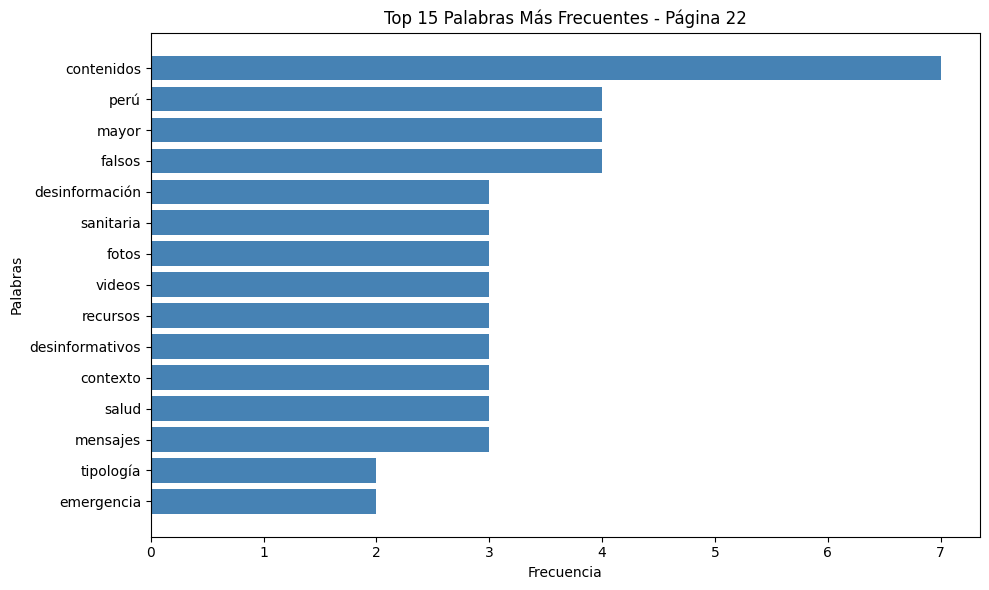

In [ ]:
import nltk
import matplotlib.pyplot as plt

def graficar_top_15_palabras(tokens_limpios):
    frecuencia = nltk.FreqDist(tokens_limpios)
    mas_comunes = frecuencia.most_common(15)

    # Separar palabras y conteos (invertidos para mostrar el mayor arriba)
    palabras = [item[0] for item in mas_comunes][::-1]
    conteos = [item[1] for item in mas_comunes][::-1]

    plt.figure(figsize=(10, 6))
    plt.barh(palabras, conteos, color='steelblue')
    plt.xlabel('Frecuencia')
    plt.ylabel('Palabras')
    plt.title('Top 15 Palabras Más Frecuentes - Página 22')
    plt.tight_layout()
    plt.show()

graficar_top_15_palabras(tokens_limpios)

# Dentro de las 15 palabras más importantes de la página 22, me aparece "et". Que significa "y otros" para citas y referencias académicas.

# No me aporta valor al análisis, con lo cual lo elimino para que me aparezca otra palabra importante.

In [ ]:
def filtrar_tokens_extra(tokens, palabras_a_excluir=['et']):
    return [token for token in tokens if token not in palabras_a_excluir]

tokens_limpios = filtrar_tokens_extra(tokens_limpios, palabras_a_excluir=['et'])

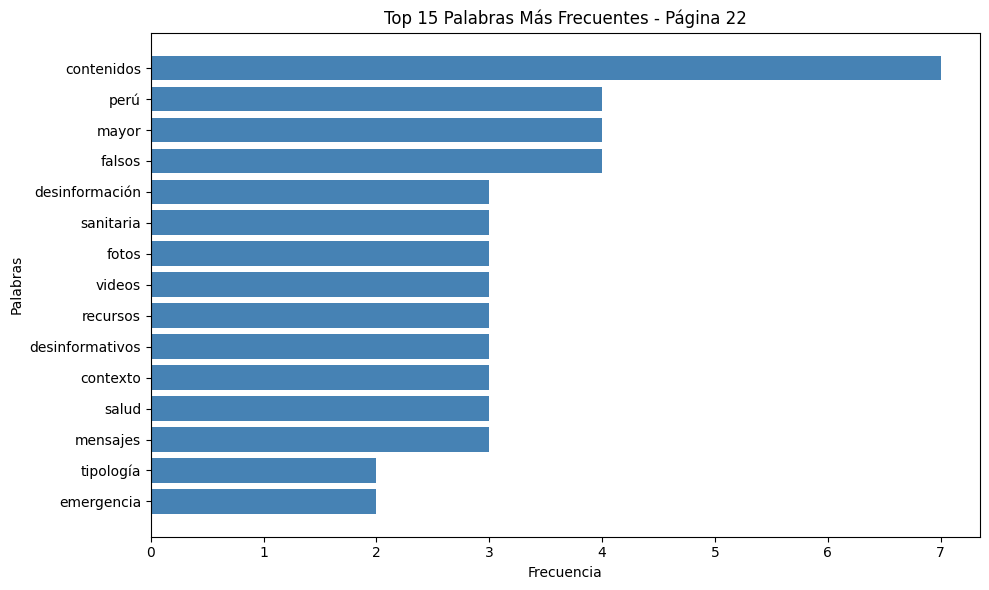

In [ ]:
graficar_top_15_palabras(tokens_limpios)

# Ahora logro visualizar los temas más tratados en la página 22, la cual es parte final de las conclusiones del informe.

# Podemos notar lo que sería un breve punteo de los temas concluidos:

* # Contenidos: Se analizan contenidos sobre si informan o desinforman.
* # Perú: De qué país son estos contenidos.
* # Falsos: Características de gran parte de estos contenidos y uno de los principales motivos del informe.
* # Desinformación: Otro tema clave que además es parte del título.
* # Sanitaria, Salud, Emergencia: En este caso, se da en un contexto (palabra que también figura) de crisis sanitaria mundial. La última es la última palabra de estas 15 palabras clave que aparece gracias a una correcta limpieza (sacamos el "et" que no nos aportaba mucho para este caso).
* # Fotos, Videos: Medios por los cuales se expande esa desinformación.
* # Mensajes, Tipología: Los mensajes y sus tipos para expandir ese contenido falso.

# Usamos el MiniBatchNMF, uno de los que vimos en clases.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import MiniBatchNMF
from sklearn.feature_extraction.text import TfidfVectorizer

def graficar_top_15_mbnmf(tokens_limpios):
    texto = [" ".join(tokens_limpios)]
    vectorizer = TfidfVectorizer()
    X = vectorizer.fit_transform(texto)
    feature_names = vectorizer.get_feature_names_out()

    mbnmf = MiniBatchNMF(n_components=1, random_state=1)
    mbnmf.fit(X)

    topic = mbnmf.components_[0]
    top_indices = topic.argsort()[-15:]

    palabras = feature_names[top_indices]
    pesos = topic[top_indices]

    plt.figure(figsize=(10, 6))
    plt.barh(palabras, pesos, color='steelblue')
    plt.xlabel('Importancia (TF-IDF)')
    plt.ylabel('Palabras')
    plt.title('Top 15 Palabras (MiniBatchNMF) - Página 22')
    plt.tight_layout()
    plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/decomposition/_nmf.py:133: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(res * 2)


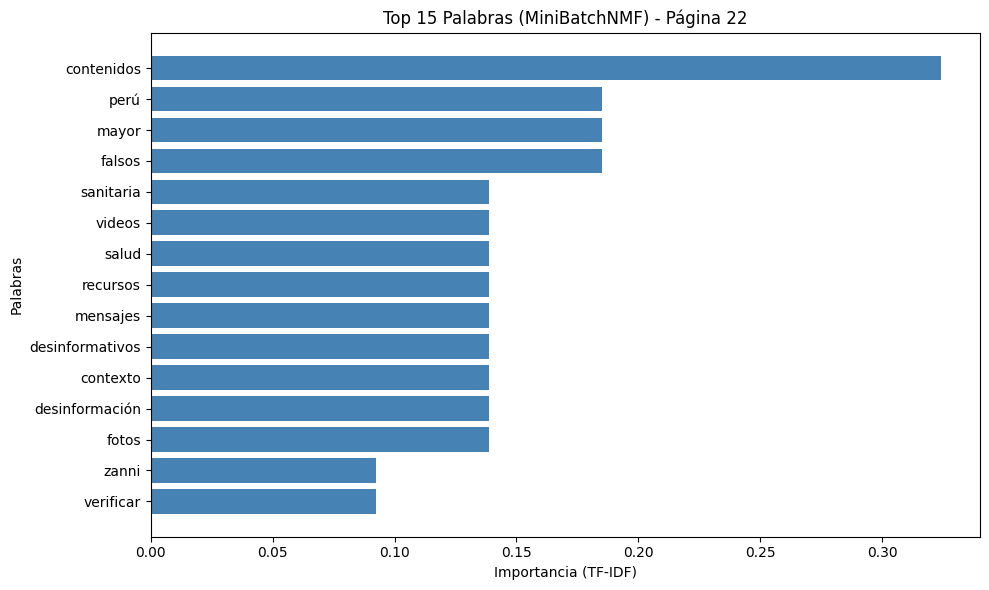

In [ ]:
graficar_top_15_mbnmf(tokens_limpios)

# Finalmente, hacemos una nube de palabras, para unirlo con el TP1.

# La nube de palabras, mostrará las mismas (recorte de las 15 más nombradas de la página 22), pero veremos que la recepción puede llegar a ser distinta, ya que es más visual a nivel imágenes.

In [ ]:
!pip install --upgrade pillow<11.0.0 wordcloud

/bin/bash: line 1: 11.0.0: No such file or directory


In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

def generar_wordcloud_verde(tokens_limpios):
    texto_unido = " ".join(tokens_limpios)

    wc = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap='Dark2',
        max_words=15,
        random_state=42
    ).generate(texto_unido)

    plt.figure(figsize=(10, 6))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title('Nube de Palabras - Página 22', fontsize=16)
    plt.tight_layout()
    plt.show()

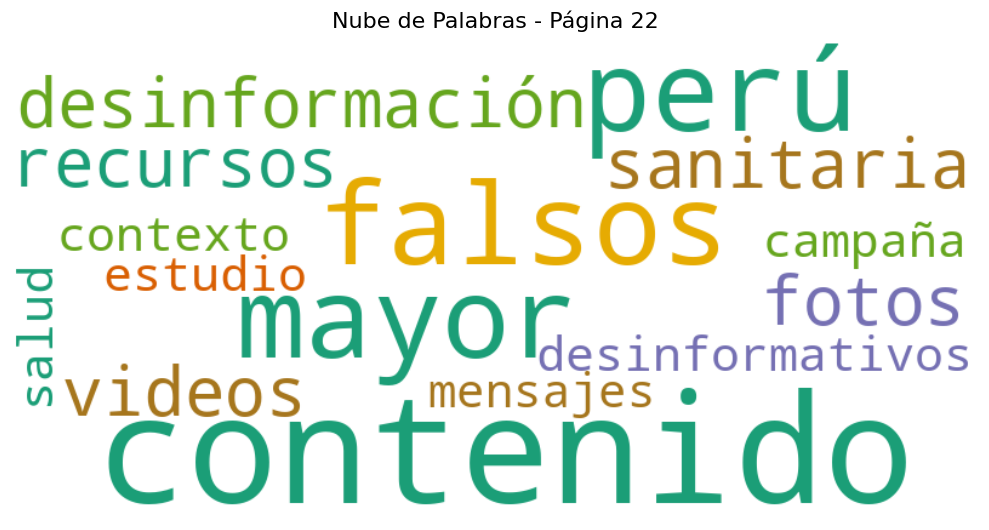

In [ ]:
generar_wordcloud_verde(tokens_limpios)

#  **5. Conclusiones.**

# Gestionar los contenidos utilizando estas herramientas, como PyMuPDF, PDFplumber, y además el análisis de tópicos, es muy útil para realizar un análisis minucioso y preciso de grandes volúmenes de datos, por detectar determinados patrones, temas recurrentes, palabras más utilizadas, hasta poder evaluar los niveles de objetividad de determinados artículos.

# De esta forma, y con una labor adecuada del ser humano, el entrenamiento de modelos del habla puede ser lo más ético, objetivo e igualitario posible, al vertirle información lo más libre de sesgos posibles.

# Mi tema elegido, también funciona metafóricamente a los que puede llegar a hacerse con la IA y su mala utilización de contenidos y saberes.

# Estamos en un punto intermedio con las herramientas más poderosas, de un lado tenémos la información y del otro la desinformación. El tema es que estamos igual de lejos de ambos lados y depende de nosotros como sociedad a cual acercarnos.

# Enlace al chat Gemini Pro:

# https://gemini.google.com/app/4f1277d05516ca27?utm_source=app_launcher&utm_medium=owned&utm_campaign=base_all